# 03 · Feature Engineering and Leakage Control

How features are built and why none of them can see the future.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


### Timing convention

A row keyed `(sku, t)` is a decision taken at the **start of trading day t**.

* features — may use demand observed on `t-1` and earlier
* target — `future_7d_demand` = demand on days `t .. t+6`

So demand on day `t` is part of the **label**, never an input.

In [2]:
from xaierp.features.builder import (
    FEATURE_GROUPS, classification_features, load_features,
    regression_features)
feats = load_features()
print(f'{len(feats):,} rows x {feats.shape[1]} columns')
print(f"{feats['stock_code'].nunique()} SKUs, "
      f"{feats['date'].min().date()} -> {feats['date'].max().date()}")

99,787 rows x 74 columns
200 SKUs, 2010-01-12 -> 2011-12-02


## Feature groups

In [3]:
for g, cols in FEATURE_GROUPS.items():
    present = [c for c in cols if c in feats.columns]
    print(f'{g:<10} ({len(present):>2}): {present}')

calendar   (14): ['day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 'month', 'quarter', 'year', 'is_weekend', 'is_month_start', 'is_month_end', 'is_quarter_end', 'is_bank_holiday', 'days_to_bank_holiday', 'is_q4_peak']
lag        ( 4): ['lag_1', 'lag_7', 'lag_14', 'lag_28']
rolling    (15): ['rolling_mean_7', 'rolling_std_7', 'rolling_max_7', 'rolling_min_7', 'zero_rate_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_max_14', 'rolling_min_14', 'zero_rate_14', 'rolling_mean_28', 'rolling_std_28', 'rolling_max_28', 'rolling_min_28', 'zero_rate_28']
trend      ( 3): ['demand_momentum', 'demand_momentum_ratio', 'demand_cv_28']
price      ( 4): ['price_lag_1', 'price_baseline_28', 'price_discount_pct', 'is_price_cut']
returns    ( 1): ['returns_mean_28']
sku        ( 2): ['sku_rank', 'median_price']


In [4]:
reg = regression_features(feats)
clf = classification_features(feats)
print(f'regression features    : {len(reg)}')
print(f'classification features: {len(clf)}')
print(f'inventory-only extras  : {sorted(set(clf) - set(reg))}')

regression features    : 43
classification features: 52
inventory-only extras  : ['current_stock', 'days_of_cover', 'inventory_position', 'lead_time_days', 'moq', 'pack_size', 'stock_vs_leadtime_demand', 'supplier_reliability', 'unit_cost']


The forecaster deliberately does **not** see stock level. How much is on the shelf does not change how much customers want; including it would model the replenishment policy rather than demand.

## Demonstrating that the lag really lags

In [5]:
from xaierp.features.lags import add_lag_features, add_rolling_features
toy = pd.DataFrame({'stock_code': ['A'] * 12,
                    'date': pd.date_range('2024-01-01', periods=12),
                    'demand': np.arange(1, 13, dtype=float)})
t = add_rolling_features(add_lag_features(toy, [1, 7]), [3])
t[['date', 'demand', 'lag_1', 'lag_7', 'rolling_mean_3', 'rolling_max_3']]

,date,demand,lag_1,lag_7,rolling_mean_3,rolling_max_3
0,2024-01-01,1.0,NaN,NaN,NaN,NaN
1,2024-01-02,2.0,1.0,NaN,NaN,NaN
2,2024-01-03,3.0,2.0,NaN,NaN,NaN
3,2024-01-04,4.0,3.0,NaN,2.0,3.0
4,2024-01-05,5.0,4.0,NaN,3.0,4.0
5,2024-01-06,6.0,5.0,NaN,4.0,5.0
6,2024-01-07,7.0,6.0,NaN,5.0,6.0
7,2024-01-08,8.0,7.0,1.0,6.0,7.0
8,2024-01-09,9.0,8.0,2.0,7.0,8.0
9,2024-01-10,10.0,9.0,3.0,8.0,9.0


On a strictly increasing series every 'past' feature must be strictly below today's value — and `rolling_max_3` equals exactly yesterday's demand, proving the window ends at `t-1`. This is asserted in `tests/test_no_leakage.py`.

## The target

In [6]:
from xaierp.features.builder import add_target
tt = add_target(toy, horizon=7)
tt[['date', 'demand', 'future_7d_demand']]

,date,demand,future_7d_demand
0,2024-01-01,1.0,28.0
1,2024-01-02,2.0,35.0
2,2024-01-03,3.0,42.0
3,2024-01-04,4.0,49.0
4,2024-01-05,5.0,56.0
5,2024-01-06,6.0,63.0
6,2024-01-07,7.0,NaN
7,2024-01-08,8.0,NaN
8,2024-01-09,9.0,NaN
9,2024-01-10,10.0,NaN


## Chronological split

In [7]:
g = feats.groupby('split')['date'].agg(['min', 'max', 'count'])
display(g.loc[['train', 'val', 'test']])
print('\nNo date appears in two splits:',
      g.loc['train','max'] < g.loc['val','min'] <= g.loc['val','max'] < g.loc['test','min'])

,min,max,count
split,,,
train,2010-01-12,2011-05-15,66859
val,2011-05-16,2011-08-23,16239
test,2011-08-24,2011-12-02,16689



No date appears in two splits: True


A **random** split would place day `t+1` in train and day `t` in test for the same SKU. Consecutive days share nearly all of their rolling-window history, so that leaks the answer and inflates every score. Splitting on global date cut-offs prevents it.

## Target distribution

count    99787.000000
mean       228.517873
std        364.037871
min          0.000000
25%         39.000000
50%        119.000000
75%        282.000000
max       9888.000000
Name: future_7d_demand, dtype: float64


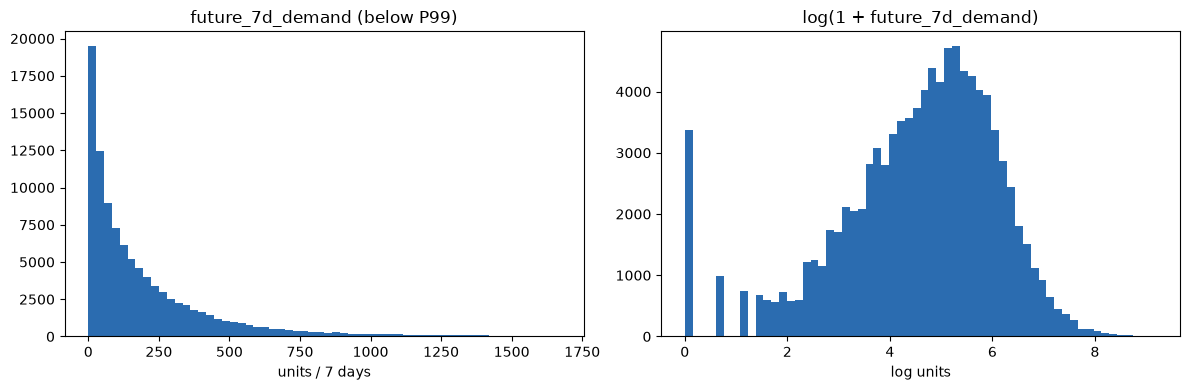

In [8]:
y = feats['future_7d_demand']
print(y.describe())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y[y <= y.quantile(0.99)], bins=60, color='#2b6cb0')
ax[0].set_title('future_7d_demand (below P99)'); ax[0].set_xlabel('units / 7 days')
ax[1].hist(np.log1p(y), bins=60, color='#2b6cb0')
ax[1].set_title('log(1 + future_7d_demand)'); ax[1].set_xlabel('log units')
plt.tight_layout(); plt.show()